In [2]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/data
!unzip -oq "/content/drive/MyDrive/WBC-Folder/PBC_dataset_normal_DIB.zip" -x "__MACOSX/*" -d /content/data
!git clone -q https://github.com/asn104610/WBC-Differentiator-v.1.git /content/repo

import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import transforms, models
from PIL import Image

root = "/content/data/PBC_dataset_normal_DIB"

def fix_path(p, label):
    name = p.replace("\\", "/").split("/")[-1]
    return f"{root}/{label}/{name}"

test_df = pd.read_csv("/content/repo/test.csv")
test_df["path"] = [fix_path(p, l) for p, l in zip(test_df["path"], test_df["label"])]
classes = sorted(test_df["label"].unique())

tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

device = "cuda"
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model.load_state_dict(torch.load("/content/drive/MyDrive/WBC-Folder/resnet18_wbc_v2.pt", map_location=device))
model = model.to(device).eval()
print("ready:", classes)

Mounted at /content/drive
ready: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


In [3]:
%pip install -q grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


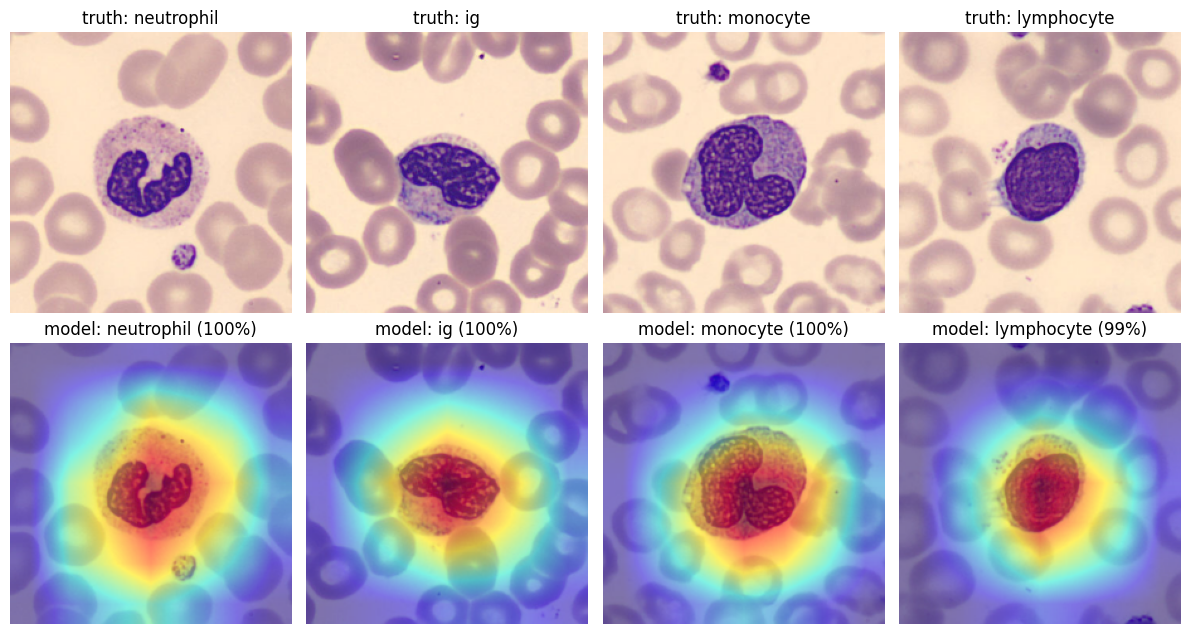

In [4]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

cam = GradCAM(model=model, target_layers=[model.layer4[-1]])

def heatmap(path):
    img = Image.open(path).convert("RGB")
    x = tfm(img).unsqueeze(0).to(device)
    rgb = np.array(img.resize((224, 224))).astype(np.float32) / 255.0
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0].cpu()
    pred = probs.argmax().item()
    grayscale = cam(input_tensor=x, targets=None)[0]
    overlay = show_cam_on_image(rgb, grayscale, use_rgb=True)
    return rgb, overlay, classes[pred], probs[pred].item()

show_classes = ["neutrophil", "ig", "monocyte", "lymphocyte"]
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for k, cls in enumerate(show_classes):
    row = test_df[test_df["label"] == cls].sample(1, random_state=3).iloc[0]
    rgb, overlay, pred, conf = heatmap(row["path"])
    axes[0, k].imshow(rgb)
    axes[0, k].set_title(f"truth: {cls}")
    axes[1, k].imshow(overlay)
    axes[1, k].set_title(f"model: {pred} ({conf:.0%})")
    axes[0, k].axis("off")
    axes[1, k].axis("off")
plt.tight_layout()
plt.show()

test accuracy: 0.986


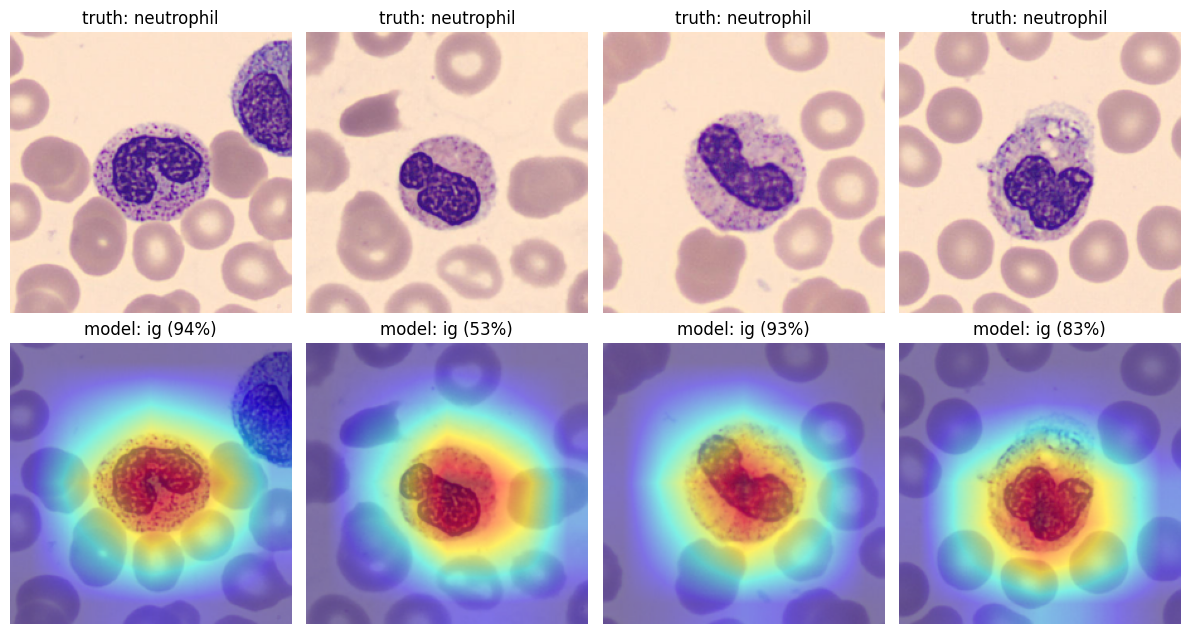

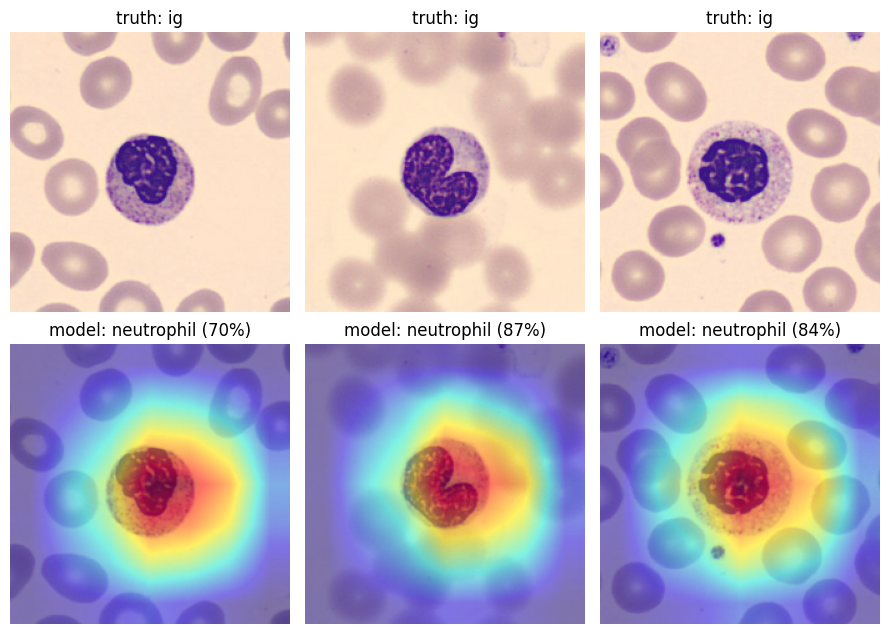

In [5]:
preds = []
with torch.no_grad():
    for i in range(0, len(test_df), 64):
        batch = torch.stack([tfm(Image.open(p).convert("RGB")) for p in test_df["path"].iloc[i:i+64]]).to(device)
        preds += model(batch).argmax(1).cpu().tolist()
test_df["pred"] = [classes[i] for i in preds]
print("test accuracy:", round((test_df["pred"] == test_df["label"]).mean(), 3))

def show_mistakes(true_label, pred_label, n=4):
    rows = test_df[(test_df["label"] == true_label) & (test_df["pred"] == pred_label)].head(n)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6.5))
    for a in axes.flat:
        a.axis("off")
    for k, (_, r) in enumerate(rows.iterrows()):
        rgb, overlay, pred, conf = heatmap(r["path"])
        axes[0, k].imshow(rgb)
        axes[0, k].set_title(f"truth: {true_label}")
        axes[1, k].imshow(overlay)
        axes[1, k].set_title(f"model: {pred} ({conf:.0%})")
    plt.tight_layout()
    plt.show()

show_mistakes("neutrophil", "ig")
show_mistakes("ig", "neutrophil", n=3)

In [6]:
confs = []
with torch.no_grad():
    for i in range(0, len(test_df), 64):
        batch = torch.stack([tfm(Image.open(p).convert("RGB")) for p in test_df["path"].iloc[i:i+64]]).to(device)
        confs += F.softmax(model(batch), dim=1).max(1).values.cpu().tolist()
test_df["conf"] = confs
wrong = test_df["pred"] != test_df["label"]

for t in [0.90, 0.95, 0.99]:
    flagged = test_df["conf"] < t
    print(f"threshold {t:.2f}: flagged {flagged.mean():.1%} of cells | "
          f"catches {(flagged & wrong).sum()} of {wrong.sum()} mistakes")

threshold 0.90: flagged 3.2% of cells | catches 22 of 36 mistakes
threshold 0.95: flagged 4.6% of cells | catches 28 of 36 mistakes
threshold 0.99: flagged 9.4% of cells | catches 32 of 36 mistakes


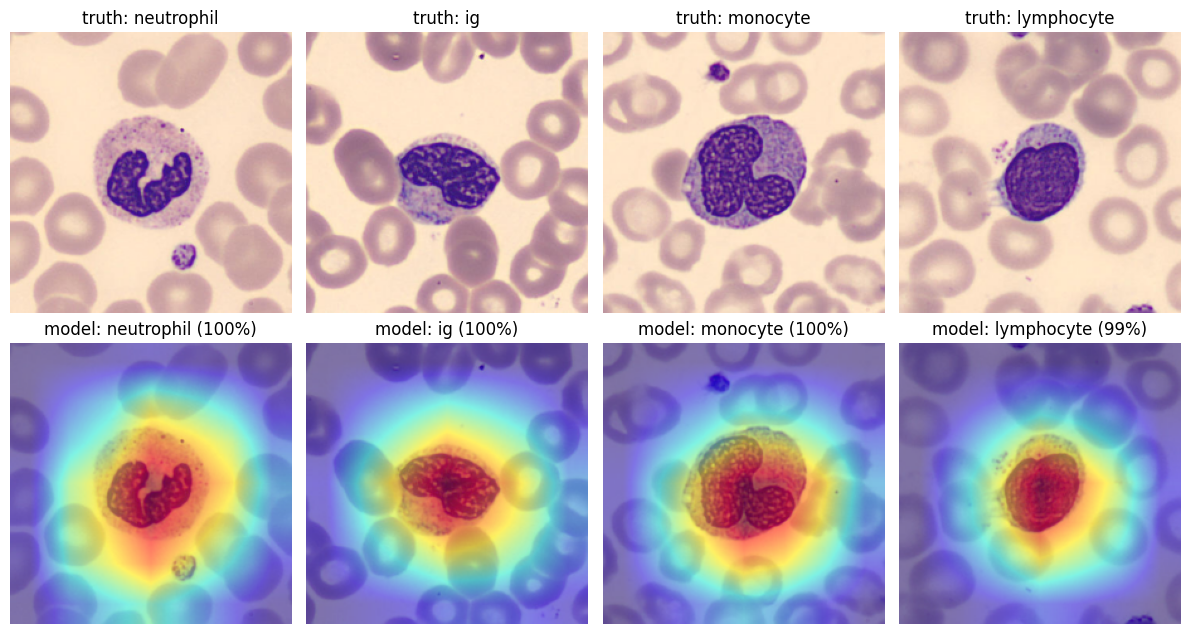

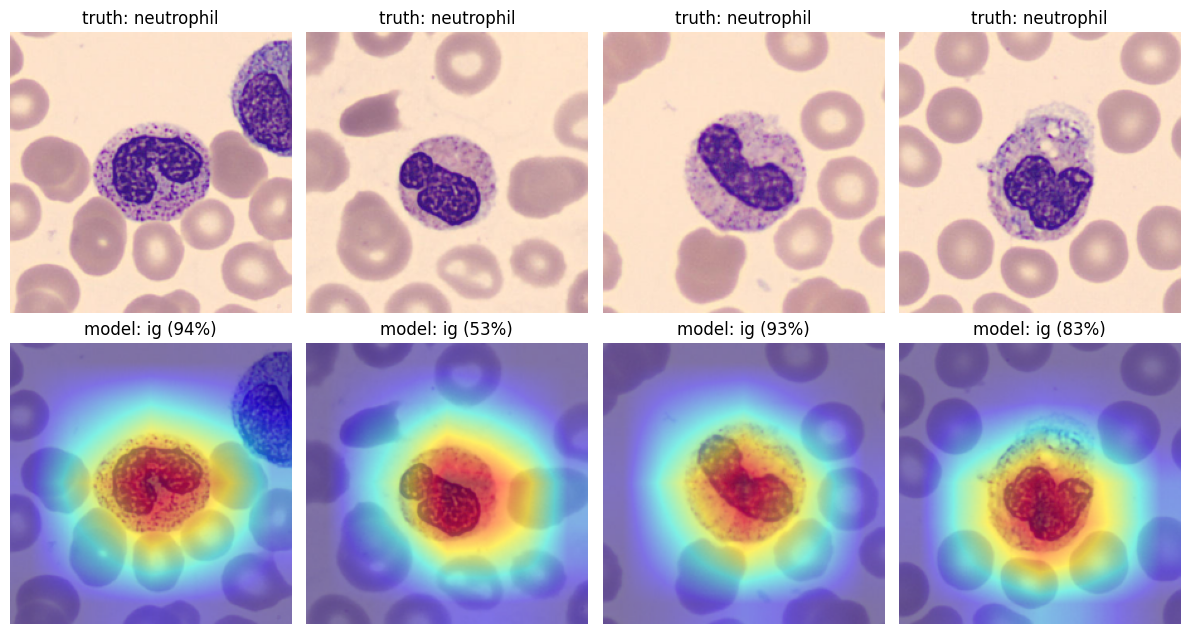

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
from google.colab import files

def save_grid(rows_df, filename, n=4):
    rows = rows_df.head(n)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6.5))
    for a in axes.flat:
        a.axis("off")
    for k, (_, r) in enumerate(rows.iterrows()):
        rgb, overlay, pred, conf = heatmap(r["path"])
        axes[0, k].imshow(rgb)
        axes[0, k].set_title(f"truth: {r['label']}")
        axes[1, k].imshow(overlay)
        axes[1, k].set_title(f"model: {pred} ({conf:.0%})")
    plt.tight_layout()
    plt.savefig(filename, dpi=130)
    plt.show()

easy = pd.concat([test_df[test_df["label"] == c].sample(1, random_state=3)
                  for c in ["neutrophil", "ig", "monocyte", "lymphocyte"]])
save_grid(easy, "heatmaps_correct.png")

miss = test_df[(test_df["label"] == "neutrophil") & (test_df["pred"] == "ig")]
save_grid(miss, "heatmaps_neutrophil_called_ig.png")

files.download("heatmaps_correct.png")
files.download("heatmaps_neutrophil_called_ig.png")